# 04 · Tuning de los tres mejores candidatos

30 configuraciones por cada una de las tres mejores familias **para t+3** (90 nested runs). Búsqueda aleatoria reproducible con ParameterSampler y evaluación explícita en los mismos folds; facilita registrar cada modelo y su evidencia.

In [2]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.datos import DATA, DOCS, EVIDENCE
from src.datos import execute
HAS_DATA = (DATA / "obt.parquet").exists()
display(Markdown("**OBT real local disponible**" if HAS_DATA else
    "**PENDIENTE:** faltan credenciales Snowflake válidas y snapshot. Este notebook no contiene resultados empíricos del ECU 911."))


**OBT real local disponible**

## Espacios predefinidos

Regularización y learning rate en escala logarítmica; profundidad, hojas y tamaños en rangos acotados. Se evalúa la mejora sobre el default. Si no supera la mayor SD entre pliegues de ambas versiones, se conserva el default para selección. No se abre test.

|Familia|Espacio disponible|
|---|---|
|Logística|C log 1e-4–1e3; ponderación None/balanced; 500/1000 iteraciones|
|Random forest|80–400 árboles; profundidad None/6/12/20; hoja mínima 1–30; max_features sqrt/.3/.7; ponderación|
|Hist boosting|LR log .01–.3; 80–300 iter.; 7–63 hojas; L2 log 1e-4–10; hoja mínima 10–60|
|MLP|32/64/100/(64,32); alpha log 1e-6–.1; LR log 1e-4–1e-2; 200/400 iter.; early stopping|
|GaussianNB|var_smoothing log 1e-12–1e-3|

Se ejecutan únicamente los espacios de las tres mejores familias de t+3.


🏃 View run tuning-padre-t3-hist_boosting at: http://127.0.0.1:5001/#/experiments/1/runs/57c202ec90024ca6b9ac3517c72bbfe2
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
INICIO tuning t+3 random_forest {'class_weight': None, 'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 22, 'n_estimators': 388}


2026/11/12 10:40:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN tuning t+3 random_forest: AP_CV=0.22745 ± 0.05992; ajuste=864.7s
🏃 View run tuning-t3-random_forest at: http://127.0.0.1:5001/#/experiments/1/runs/57694432bb534961995f068c7d234198
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
INICIO tuning t+3 random_forest {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 6, 'n_estimators': 271}


2026/11/12 10:43:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN tuning t+3 random_forest: AP_CV=0.20803 ± 0.04742; ajuste=184.6s
🏃 View run tuning-t3-random_forest at: http://127.0.0.1:5001/#/experiments/1/runs/a1361bd1beb34aa99f97b61028b82f0d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
INICIO tuning t+3 random_forest {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 12, 'n_estimators': 393}


2026/11/12 10:45:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (107 outputs left out)

2026/11/12 12:24:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


FIN tuning t+3 logistica: AP_CV=0.13761 ± 0.02798; ajuste=2.1s
🏃 View run tuning-t3-logistica at: http://127.0.0.1:5001/#/experiments/1/runs/f1eb624ced7d4178a6dee5bf74c823cc
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run tuning-padre-t3-logistica at: http://127.0.0.1:5001/#/experiments/1/runs/faeec43ddbb143278180b4c39d527101
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,horizon,name,cv_ap_mean,cv_ap_std,improvement,improvement_exceeds_std,params,run_id
0,3,hist_boosting,0.217616,0.051647,0.004329,False,"{'l2_regularization': 0.3603377510962438, 'lea...",67be6db83f304e70ae814b6d505ff398
1,3,random_forest,0.234648,0.051560,0.024536,False,"{'class_weight': None, 'max_depth': None, 'max...",dbb1b1a12ca8427682d0457750a8098a
2,3,logistica,0.201630,0.033126,0.020856,False,"{'C': 67.1581131106993, 'class_weight': 'balan...",2a6ffb8c53cb4edcb1a3d1c5c7912191


,name,horizon,phase,run_id,model_uri,train_ap,cv_ap_mean,cv_ap_std,gap,fit_seconds,...,elapsed_seconds,threshold,precision_constraint_feasible,params,learning_rate,warnings,fold_ap,improvement,improvement_exceeds_std,default_run_id
0,hist_boosting,3,tuning,820a9c9431554dee92c02fbcca3aead5,models:/m-4b7c6583db0a4955b85705f577af237b,0.317283,0.209220,0.053525,0.108063,29.097282,...,35.595653,0.213184,True,"{'l2_regularization': 0.0074593432857265485, '...",0.253700,0,"[0.15598578596317553, 0.20864313233359424, 0.2...",NaN,NaN,NaN
1,hist_boosting,3,tuning,937f70cc32a04d799a05178498026d80,models:/m-52d65ed237e442ffa9f174db7c573e4f,0.236100,0.197286,0.037662,0.038814,51.977071,...,63.192264,0.162986,True,"{'l2_regularization': 0.0006026889128682511, '...",0.016999,0,"[0.15923092767399122, 0.19808522242570872, 0.2...",NaN,NaN,NaN
2,hist_boosting,3,tuning,73ff70a20ebb4321a973cbca4ac52b5c,models:/m-f0b580a939524113bb37807d11f34e44,0.259612,0.206536,0.042249,0.053076,81.257380,...,99.265339,0.174576,True,"{'l2_regularization': 0.004661686413912772, 'l...",0.016257,0,"[0.16124072557232888, 0.21349106771595047, 0.2...",NaN,NaN,NaN
3,hist_boosting,3,tuning,b22c1324ee284392953778af51c26c92,models:/m-c3b65574201348cc94269ea559f0ab08,0.368796,0.210886,0.054520,0.157909,34.215800,...,42.238842,0.205340,True,"{'l2_regularization': 0.40737451960583815, 'le...",0.243420,0,"[0.15473825188848805, 0.2143026076780324, 0.26...",NaN,NaN,NaN
4,hist_boosting,3,tuning,27d1eb6b32fa46679865634fca5ad664,models:/m-ea1def10aec242b5aec1f4ae2b6173b9,0.330230,0.214329,0.051258,0.115902,68.204853,...,82.824912,0.193748,True,"{'l2_regularization': 0.0033205591037519565, '...",0.059584,0,"[0.1589839180071372, 0.2238327014594322, 0.260...",NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,logistica,3,tuning,17373ea3e5b141949ef971d14ec348ed,models:/m-1a7f343cfd6345a5b801a336dc6b47ba,0.210351,0.201271,0.038009,0.009080,21.735255,...,22.838971,0.739348,True,"{'C': np.float64(612.4806805925963), 'class_we...",NaN,0,"[0.16105893522542347, 0.2061471901727524, 0.23...",NaN,NaN,NaN
86,logistica,3,tuning,599429a85d4e4901b6dd38809c66bcc9,models:/m-7e80c28e74b5461499e5fc69ea32ab4d,0.209661,0.200787,0.038661,0.008874,20.544169,...,21.535998,0.739087,True,"{'C': np.float64(377.1313111077982), 'class_we...",NaN,0,"[0.16030394958405278, 0.20473345839939752, 0.2...",NaN,NaN,NaN
87,logistica,3,tuning,1721ce11a6fa432bba8be08c033486d9,models:/m-671217f322bc4dffad141b3526dadf18,0.205247,0.186286,0.032680,0.018961,14.874433,...,15.857045,0.772057,True,"{'C': np.float64(1.5321449415450707), 'class_w...",NaN,0,"[0.16024229426721237, 0.1756601991336905, 0.22...",NaN,NaN,NaN
88,logistica,3,tuning,1b040a816e1148f0a3b48174d44c6820,models:/m-48278b289571467d9bb9a04251f0339f,0.144665,0.135818,0.028248,0.008846,2.209606,...,3.221728,0.180520,True,"{'C': np.float64(0.0004163394022669378), 'clas...",NaN,0,"[0.11709998141789349, 0.12204385165883655, 0.1...",NaN,NaN,NaN


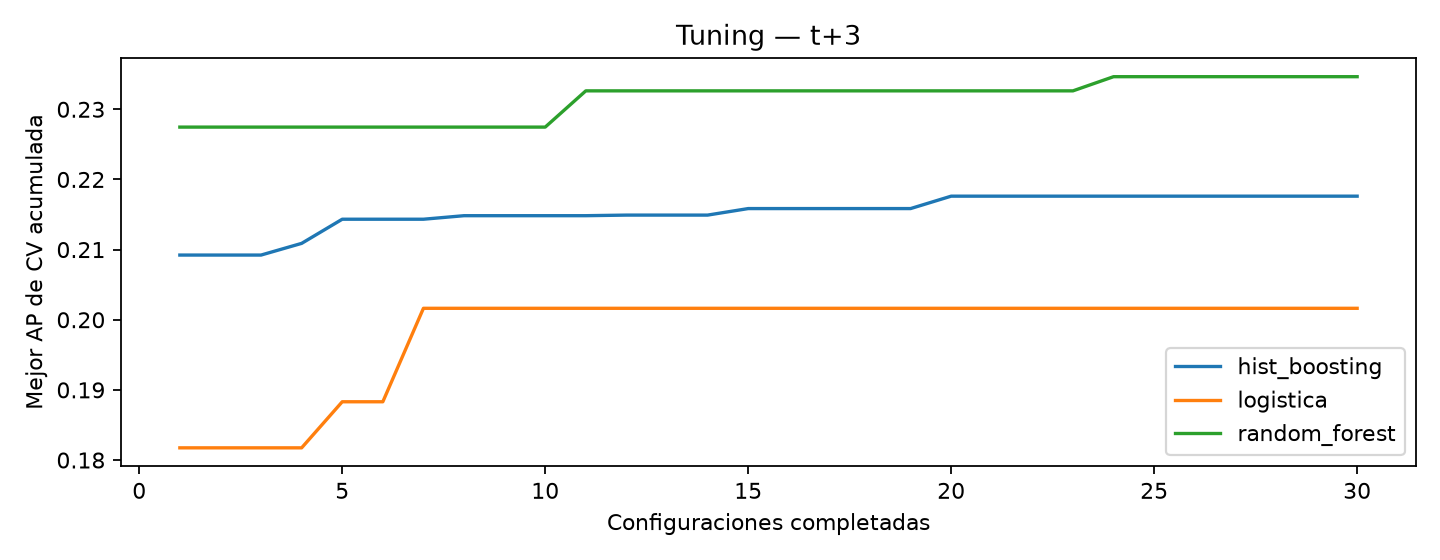

In [3]:
from src.datos import models, spaces
from joblib import parallel_config
if HAS_DATA:
    # n_jobs=None de Random Forest hereda 4 hilos de este contexto.
    # Se conservan hiperparámetros, semilla, folds y cachés existentes.
    with parallel_config(backend="threading", n_jobs=4):
        tuned = execute("tuning")
    display(pd.DataFrame(tuned)[["horizon", "name", "cv_ap_mean", "cv_ap_std", "improvement", "improvement_exceeds_std", "params", "run_id"]])
    display(pd.read_csv(EVIDENCE / "tuning_trials.csv"))
    from src.datos import plot_tuning
    display(Image(filename=str(plot_tuning(pd.read_csv(EVIDENCE / "tuning_trials.csv")))))


La búsqueda de hiperparámetros y la selección usan la misma CV: puede haber optimismo de selección. El hold-out final permanece independiente y solo se abre después de congelar finalistas y umbrales.